# Rain-risk planning in Malabe

This notebook will estimate the chance that an outdoor event in Malabe encounters a wet hour during October or November. It will use historical ERA5 precipitation and a first-order wet/dry Markov model to compare candidate start times and show how the result changes with event duration and the rainfall threshold. The estimates are intended for advance planning with historical weather patterns.

## 1. Problem and question

Which hourly start from 08:00 through 15:00 local time gives a three-hour outdoor event in Malabe the lowest rain-exposure risk during October and November? How does that risk compare with starting at 13:00?

An event is exposed if at least one of its hourly precipitation totals is **at or above 0.2 mm** in the default scenario. The threshold is a planning assumption. Report October and November separately and combine them with weights of $31/61$ and $30/61$ when event dates are equally likely across the season.

## 2. Model, assumptions and equations

Let $Y_h$ be the estimated precipitation in millimetres during the local interval $[h,h+1)$. For a threshold $\tau$ in millimetres, the state $X_h=\mathbf{1}\{Y_h\geq\tau\}$ is 0 for dry and 1 for wet. Use valid, consecutive training hours to count transitions within a local day.

For month $m$, let $q_{m,h}$ be the observed wet fraction at hour $h$. For destination hour $h$, let $n_{m,h}(i,j)$ count transitions from previous state $i$ to current state $j$. Smooth the two possible outcomes in each row with a count of 0.5:

$$
p_{m,h}(i,j)=
\frac{n_{m,h}(i,j)+0.5}{\sum_{k=0}^{1}n_{m,h}(i,k)+1}.
$$

The first hour uses $q_{m,s}$ at start hour $s$. Each later hour uses its transition probabilities and the preceding state. For $d$ event hours, the model's exposure probability is one minus the probability of staying dry throughout:

$$
P(\text{exposure}\mid m,s,d)=
1-(1-q_{m,s})\prod_{h=s+1}^{s+d-1}p_{m,h}(0,0).
$$

The empty product is 1 for a one-hour event. The independent-hour comparison uses $1-\prod_{h=s}^{s+d-1}(1-q_{m,h})$. The model applies three concepts: **Markov chains** for rainfall persistence, **input modelling and random variate generation** for fitting probabilities and drawing states, and **Monte Carlo simulation and the law of large numbers** for estimating exposure over repeated trials.

## 3. Implementation

Install the packages in the first code cell. The configuration cell defines the scenarios and creates reproducible random-number streams.

In [ ]:
%pip install -q numpy pandas matplotlib

### I1 Configuration

In [1]:
from importlib.metadata import version
from pathlib import Path

import numpy as np

exports = Path("exports")
exports.mkdir(exist_ok=True)

LOCAL_TIME_ZONE = "Asia/Colombo"
TRAIN_YEARS = tuple(range(2016, 2023))
HELD_OUT_YEARS = tuple(range(2023, 2026))
MONTHS = (10, 11)
MONTH_WEIGHTS = {10: 31 / 61, 11: 30 / 61}
START_HOURS = tuple(range(8, 16))
BASELINE_START_HOUR = 13
DEFAULT_DURATION_HOURS = 3
DEFAULT_THRESHOLD_MM = 0.2
DURATIONS_HOURS = (1, 2, 3, 4)
THRESHOLDS_MM = (0.1, 0.2, 0.5, 1.0)
SEED = 4042

# Re-running this cell restarts each stream from the same seed.
main_seed, scaling_seed, bootstrap_seed = np.random.SeedSequence(SEED).spawn(3)
rng_main = np.random.default_rng(main_seed)
rng_scaling = np.random.default_rng(scaling_seed)
rng_bootstrap = np.random.default_rng(bootstrap_seed)

for package in ("numpy", "pandas", "matplotlib"):
    print(f"{package} {version(package)}")

numpy 2.5.5
pandas 3.0.1
matplotlib 3.10.0


### I2 Load data

The analysis uses one representative Malabe town point (6.90407° N, 79.95462° E). Colab loads the rainfall CSV from the published data commit. A checkout of the repository can use its local copy of the same snapshot.

In [2]:
from datetime import datetime, timezone
import json
from urllib.parse import urlencode
from urllib.request import urlopen

import pandas as pd

MALABE_LATITUDE = 6.90407
MALABE_LONGITUDE = 79.95462
ARCHIVE_URL = "https://archive-api.open-meteo.com/v1/archive"
DATA_FILE = "malabe_era5_hourly_utc.csv"
DATA_URL = "https://raw.githubusercontent.com/KumarageKPV/malabe-rain-risk/d65be4337dbf0b4e4f3f4a1722f9fc90897a5d26/data/malabe_era5_hourly_utc.csv"


def download_era5_hourly(years):
    hourly_frames = []
    query_records = []

    for year in years:
        start_date = f"{year}-09-30"
        end_date = f"{year}-12-01"
        query = urlencode({
            "latitude": MALABE_LATITUDE,
            "longitude": MALABE_LONGITUDE,
            "start_date": start_date,
            "end_date": end_date,
            "hourly": "precipitation",
            "models": "era5",
            "timezone": "GMT",
        })
        with urlopen(f"{ARCHIVE_URL}?{query}", timeout=60) as response:
            payload = json.load(response)
            response_url = response.geturl()
            retrieved_utc = datetime.now(timezone.utc).isoformat(timespec="seconds")

        hours = payload["hourly"]["time"]
        totals = payload["hourly"]["precipitation"]
        expected_hours = pd.date_range(
            start_date, f"{end_date} 23:00", freq="h", tz="UTC"
        )
        if (
            payload["utc_offset_seconds"] != 0
            or payload["hourly_units"]["precipitation"] != "mm"
        ):
            raise ValueError(f"{year}: expected UTC timestamps and millimetres.")
        if len(hours) != len(totals) or not expected_hours.equals(
            pd.to_datetime(hours, utc=True)
        ):
            raise ValueError(f"{year}: missing, extra, or out-of-order API timestamps.")

        hourly_frames.append(pd.DataFrame({"time_utc": hours, "precip_mm": totals}))
        query_records.append({
            "year": year,
            "query": response_url,
            "requested_latitude": MALABE_LATITUDE,
            "requested_longitude": MALABE_LONGITUDE,
            "grid_latitude": payload["latitude"],
            "grid_longitude": payload["longitude"],
            "retrieved_utc": retrieved_utc,
            "rows": len(hours),
            "missing_precipitation": sum(total is None for total in totals),
        })

    return pd.concat(hourly_frames, ignore_index=True), pd.DataFrame(query_records)

In [3]:
local_snapshot = next(
    (folder / DATA_FILE for folder in (Path("data"), Path("../data"))
     if (folder / DATA_FILE).is_file()),
    None,
)

if local_snapshot is not None:
    raw = pd.read_csv(local_snapshot)
    data_source = f"Local rainfall snapshot ({local_snapshot})"
elif DATA_URL:
    raw = pd.read_csv(DATA_URL)
    data_source = "Commit-pinned rainfall snapshot"
else:
    raw, data_queries = download_era5_hourly(TRAIN_YEARS + HELD_OUT_YEARS)
    raw.to_csv(exports / DATA_FILE, index=False)
    data_queries.to_csv(exports / "data_queries.csv", index=False)
    data_source = "Open-Meteo ERA5 archive"

print(f"{data_source}: {len(raw):,} UTC rows.")
print(raw.head().to_string(index=False))

Local rainfall snapshot (data\malabe_era5_hourly_utc.csv): 15,120 UTC rows.
        time_utc  precip_mm
2016-09-30T00:00        0.3
2016-09-30T01:00        0.1
2016-09-30T02:00        0.0
2016-09-30T03:00        0.0
2016-09-30T04:00        0.0


### I3 Prepare local hours

Open-Meteo labels each precipitation total with the UTC end of its preceding hour. In Malabe, 03:00 UTC ends at 08:30 local time. The estimate for 08:00–09:00 uses half of the totals ending at 08:30 and 09:30, assuming precipitation is spread uniformly within each source hour.

The coverage table separates missing timestamps from present rows without a valid estimate. Keep the two original bin totals for the later ±30-minute timing check. Use the same available dates when comparing timing assumptions.

In [4]:
from calendar import monthrange


def prepare_local_hours(raw_rain):
    rain = raw_rain.loc[:, ["time_utc", "precip_mm"]].copy()
    rain["time_utc"] = pd.to_datetime(rain["time_utc"], utc=True)
    rain["precip_mm"] = pd.to_numeric(rain["precip_mm"], errors="raise")

    timestamps = rain["time_utc"]
    if timestamps.isna().any() or timestamps.duplicated().any():
        raise ValueError("Expected one non-missing UTC timestamp per source row.")
    if not timestamps.eq(timestamps.dt.floor("h")).all():
        raise ValueError("Expected UTC timestamps on the hour.")
    observed = rain["precip_mm"].dropna()
    if not np.isfinite(observed).all() or observed.lt(0).any():
        raise ValueError("Precipitation totals must be finite and nonnegative.")

    rain = rain.sort_values("time_utc").reset_index(drop=True)
    rain["local_end"] = rain["time_utc"].dt.tz_convert(LOCAL_TIME_ZONE)
    if not rain["local_end"].dt.minute.eq(30).all():
        raise ValueError("Expected Malabe source windows to end on the half hour.")

    next_end = rain["local_end"].shift(-1)
    consecutive = next_end.sub(rain["local_end"]).eq(pd.Timedelta(hours=1))
    next_total = rain["precip_mm"].shift(-1)
    rain["local_start"] = rain["local_end"].dt.floor("h")
    rain["earlier_bin_mm"] = rain["precip_mm"].where(consecutive)
    rain["later_bin_mm"] = next_total.where(consecutive)
    rain["local_hour_mm"] = (
        (rain["earlier_bin_mm"] + rain["later_bin_mm"]) / 2
    ).round(2)
    rain["local_date"] = rain["local_start"].dt.date
    rain["year"] = rain["local_start"].dt.year
    rain["month"] = rain["local_start"].dt.month
    rain["hour"] = rain["local_start"].dt.hour

    season = rain.loc[rain["month"].isin(MONTHS)].copy()
    if season["local_start"].duplicated().any():
        raise ValueError("Duplicate local hourly intervals.")
    return season


def classify_wet_hours(hourly_mm, threshold_mm):
    """Return 0 or 1 for valid totals and preserve missing states."""
    return hourly_mm.ge(threshold_mm).astype("Int8").where(hourly_mm.notna())


data = prepare_local_hours(raw)
coverage_index = pd.MultiIndex.from_product(
    [TRAIN_YEARS + HELD_OUT_YEARS, MONTHS], names=["year", "month"]
)
coverage = (
    data.groupby(["year", "month"])["local_hour_mm"]
    .agg(rows_present="size", valid_hours="count")
    .reindex(coverage_index, fill_value=0)
)
coverage["expected_hours"] = [
    24 * monthrange(year, month)[1] for year, month in coverage.index
]
coverage["missing_rows"] = coverage["expected_hours"] - coverage["rows_present"]
coverage["invalid_estimates"] = coverage["rows_present"] - coverage["valid_hours"]

train = data.loc[data["year"].isin(TRAIN_YEARS)].copy()
test = data.loc[data["year"].isin(HELD_OUT_YEARS)].copy()
assert not set(train["year"]).intersection(test["year"])

print(coverage.to_string())
print(f"Train years: {sorted(train['year'].unique().tolist())} ({len(train):,} rows)")
print(f"Held-out years: {sorted(test['year'].unique().tolist())} ({len(test):,} rows)")

            rows_present  valid_hours  expected_hours  missing_rows  invalid_estimates
year month                                                                            
2016 10              744          744             744             0                  0
     11              720          720             720             0                  0
2017 10              744          744             744             0                  0
     11              720          720             720             0                  0
2018 10              744          744             744             0                  0
     11              720          720             720             0                  0
2019 10              744          744             744             0                  0
     11              720          720             720             0                  0
2020 10              744          744             744             0                  0
     11              720          720      

### I4 Fit parameters

For each threshold, fit initial wet frequencies by month and local hour. Count transitions by month and **destination hour** using valid pairs one hour apart on the same local date. Exclude hour 00 from the transition table because its preceding hour is on a different date. Smoothing assigns 0.5 to each outcome when a previous state has zero observed pairs. Those rows are flagged in the saved table.

In [5]:
def fit_hourly_markov(training, threshold_mm, rainfall_column="local_hour_mm"):
    """Fit initial wet frequencies and same-day transition rows."""
    ordered = training.sort_values("local_start").copy()
    ordered["state"] = classify_wet_hours(ordered[rainfall_column], threshold_mm)
    valid = ordered["state"].notna()

    initial_index = pd.MultiIndex.from_product(
        [MONTHS, range(24)], names=["month", "hour"]
    )
    initial = (
        ordered.groupby(["month", "hour"])["state"]
        .agg(valid_hours="count", wet_hours="sum")
        .reindex(initial_index, fill_value=0)
        .astype("int64")
    )
    initial["p_wet"] = initial["wet_hours"].div(
        initial["valid_hours"].where(initial["valid_hours"].gt(0))
    )

    previous_state = ordered["state"].shift()
    consecutive = ordered["local_start"].diff().eq(pd.Timedelta(hours=1))
    same_date = ordered["local_date"].eq(ordered["local_date"].shift())
    valid_pairs = valid & previous_state.notna() & consecutive & same_date

    pairs = ordered.loc[valid_pairs, ["month", "hour", "state"]].rename(
        columns={"state": "next_state"}
    )
    pairs["previous_state"] = previous_state.loc[valid_pairs]
    transition_index = pd.MultiIndex.from_product(
        [MONTHS, range(1, 24), (0, 1), (0, 1)],
        names=["month", "hour", "previous_state", "next_state"],
    )
    transitions = (
        pairs.groupby(list(transition_index.names)).size()
        .reindex(transition_index, fill_value=0)
        .unstack("next_state")
        .rename(columns={0: "dry_count", 1: "wet_count"})
        .rename_axis(columns=None)
    )
    transitions["observed_pairs"] = transitions["dry_count"] + transitions["wet_count"]
    denominator = transitions["observed_pairs"] + 1.0
    transitions["p_dry"] = (transitions["dry_count"] + 0.5) / denominator
    transitions["p_wet"] = (transitions["wet_count"] + 0.5) / denominator
    transitions["has_direct_evidence"] = transitions["observed_pairs"].gt(0)

    return {"initial": initial, "transitions": transitions}

In [6]:
fitted_models = {
    threshold_mm: fit_hourly_markov(train, threshold_mm)
    for threshold_mm in THRESHOLDS_MM
}

initial_table = pd.concat(
    {threshold: model["initial"] for threshold, model in fitted_models.items()},
    names=["threshold_mm"],
)
transition_table = pd.concat(
    {threshold: model["transitions"] for threshold, model in fitted_models.items()},
    names=["threshold_mm"],
)

initial_table.to_csv(exports / "fitted_initial_probabilities.csv")
transition_table.to_csv(exports / "fitted_transition_probabilities.csv")

october_initial = fitted_models[DEFAULT_THRESHOLD_MM]["initial"].loc[10]
october_transitions = fitted_models[DEFAULT_THRESHOLD_MM]["transitions"].loc[10]
october_morning = october_transitions.loc[pd.IndexSlice[8:11, :], :]

print("October initial wet probability at 0.2 mm")
print(october_initial.loc[8:11].to_string(float_format="{:.6f}".format))
print("\nOctober transitions at 0.2 mm, grouped by destination hour")
print(october_morning.to_string(float_format="{:.6f}".format))
print(f"\nInitial groups with no valid hours: {initial_table['p_wet'].isna().sum()}")
print(f"Transition rows with no direct evidence: {(~transition_table['has_direct_evidence']).sum()}")

October initial wet probability at 0.2 mm
      valid_hours  wet_hours    p_wet
hour                                 
8             217         65 0.299539
9             217         81 0.373272
10            217         99 0.456221
11            217        113 0.520737

October transitions at 0.2 mm, grouped by destination hour
                     dry_count  wet_count  observed_pairs    p_dry    p_wet  has_direct_evidence
hour previous_state                                                                             
8    0                     141         17             158 0.889937 0.110063                 True
     1                      11         48              59 0.191667 0.808333                 True
9    0                     124         28             152 0.813725 0.186275                 True
     1                      12         53              65 0.189394 0.810606                 True
10   0                     109         27             136 0.799270 0.200730             

### I5 Simulate

Use the initial wet probability for the event's first hour and one transition per later hour. The trace shows one three-hour October event and how the exposure flag changes. The Monte Carlo comparison uses independent trials with a fixed fit. The Wilson interval describes sampling error from those trials. Variation across fitting seasons is addressed separately in the sensitivity study.

In [7]:
def event_probabilities(models, threshold_mm, month, start_hour, duration_hours):
    """Get the initial wet probabilities and later state-dependent wet chances."""
    if month not in MONTHS or start_hour not in START_HOURS:
        raise ValueError("Choose a configured month and start hour.")
    if duration_hours not in DURATIONS_HOURS or threshold_mm not in models:
        raise ValueError("Choose a fitted threshold and a configured duration.")

    hours = range(start_hour, start_hour + duration_hours)
    model = models[threshold_mm]
    hourly_wet = model["initial"].loc[month, "p_wet"].reindex(hours).to_numpy()
    if not np.isfinite(hourly_wet).all():
        raise ValueError("The event includes an hour with no valid fitting data.")

    transitions_by_hour = model["transitions"].loc[month, "p_wet"].unstack()
    transition_wet = transitions_by_hour.reindex(index=hours[1:], columns=[0, 1])
    return hours, hourly_wet, transition_wet.to_numpy()


def simulate_exposure(initial_wet, transition_wet, trials, rng):
    """Return one 0/1 exposure flag per independent trial."""
    if trials <= 0:
        raise ValueError("Use a positive number of trials.")

    state = rng.random(trials) < initial_wet
    exposed = state.copy()
    for p_wet_after_dry, p_wet_after_wet in transition_wet:
        probability = np.where(state, p_wet_after_wet, p_wet_after_dry)
        state = rng.random(trials) < probability
        exposed |= state
    return exposed.astype(np.int8)


def exact_markov_exposure(initial_wet, transition_wet):
    all_dry = 1.0 - initial_wet
    for p_wet_after_dry, _ in transition_wet:
        all_dry *= 1.0 - p_wet_after_dry
    return float(1.0 - all_dry)


def independent_hour_exposure(hourly_wet):
    return float(1.0 - np.prod(1.0 - hourly_wet))


def wilson_interval(exposures, trials):
    """Return the 95% Wilson interval for a simulated proportion."""
    if trials <= 0 or not 0 <= exposures <= trials:
        raise ValueError("Expected between 0 and trials exposures and trials > 0.")

    p = exposures / trials
    z = 1.959964
    denominator = 1.0 + z * z / trials
    centre = (p + z * z / (2 * trials)) / denominator
    half_width = z * np.sqrt(
        p * (1.0 - p) / trials + z * z / (4 * trials * trials)
    ) / denominator
    return max(0.0, centre - half_width), min(1.0, centre + half_width)


def trace_event(hours, initial_wet, transition_wet, rng):
    """Show the successive random draws for one event."""
    rows = []
    state = None
    exposed = 0
    for index, hour in enumerate(hours):
        previous_state = state
        if index == 0:
            probability = initial_wet
        else:
            probability = transition_wet[index - 1, previous_state]
        draw = rng.random()
        state = int(draw < probability)
        exposed = max(exposed, state)
        rows.append({
            "local_interval": f"{hour:02d}:00–{hour + 1:02d}:00",
            "conditioning_state": "initial" if index == 0 else ("dry", "wet")[previous_state],
            "p_wet": probability,
            "uniform_draw": draw,
            "state": state,
            "exposed_so_far": exposed,
        })
    return pd.DataFrame(rows)

In [8]:
example_threshold = DEFAULT_THRESHOLD_MM
example_month = 10
example_start = 8
example_duration = DEFAULT_DURATION_HOURS
hours, hourly_wet, transition_wet = event_probabilities(
    fitted_models, example_threshold, example_month, example_start, example_duration
)

example_trace = trace_event(
    hours, hourly_wet[0], transition_wet, np.random.default_rng(SEED)
)
print(f"October, 08:00–11:00 local time, {example_threshold:g} mm threshold (trace seed {SEED})")
print(example_trace.to_string(index=False, float_format="{:.6f}".format))
print(f"Final event exposure flag: {example_trace['exposed_so_far'].iloc[-1]}")

example_trials = 20_000
example_seed = SEED + 1
verification_alpha = 0.01
verification_tolerance = np.sqrt(np.log(2 / verification_alpha) / (2 * example_trials))
flags = simulate_exposure(
    hourly_wet[0], transition_wet, example_trials, np.random.default_rng(example_seed)
)
example_exposures = int(flags.sum())
example_simulated = example_exposures / example_trials
example_exact = exact_markov_exposure(hourly_wet[0], transition_wet)
example_independent = independent_hour_exposure(hourly_wet)
wilson_low, wilson_high = wilson_interval(example_exposures, example_trials)

print(f"\nMonte Carlo seed: {example_seed}, exposures: {example_exposures:,}/{example_trials:,}")
print(f"Simulated risk: {example_simulated:.2%} (95% Wilson interval {wilson_low:.2%}–{wilson_high:.2%})")
print(f"Exact Markov risk: {example_exact:.2%}")
print(f"Independent-hour risk: {example_independent:.2%}")

October, 08:00–11:00 local time, 0.2 mm threshold (trace seed 4042)
local_interval conditioning_state    p_wet  uniform_draw  state  exposed_so_far
   08:00–09:00            initial 0.299539      0.097563      1               1
   09:00–10:00                wet 0.810606      0.478735      1               1
   10:00–11:00                wet 0.884146      0.194861      1               1
Final event exposure flag: 1

Monte Carlo seed: 4043, exposures: 10,855/20,000
Simulated risk: 54.27% (95% Wilson interval 53.58%–54.96%)
Exact Markov risk: 54.44%
Independent-hour risk: 76.13%


## 4. Verification

Toy inputs check the UTC alignment, threshold equality, missing-data handling, and limiting cases. The fitted-model test uses the October 08:00 example, with 20,000 trials and seed 4043. Its absolute-error tolerance is the two-sided Hoeffding bound with 1% error probability, set before simulation.

In [9]:
checks = []


def record_check(check, expected, obtained, tolerance=None):
    """Record exact or absolute-tolerance checks for the evidence table."""
    passed = (
        obtained == expected if tolerance is None
        else np.isclose(obtained, expected, rtol=0, atol=tolerance)
    )
    checks.append({
        "Check": check,
        "Expected": expected,
        "Obtained": obtained,
        "Tolerance": "Exact" if tolerance is None else tolerance,
        "Pass?": "PASS" if passed else "FAIL",
    })


record_check("Training and held-out years in common", 0, len(set(TRAIN_YEARS) & set(HELD_OUT_YEARS)))
record_check("Baseline and defaults in the configuration", True, (
    BASELINE_START_HOUR in START_HOURS
    and DEFAULT_DURATION_HOURS in DURATIONS_HOURS
    and DEFAULT_THRESHOLD_MM in THRESHOLDS_MM
))
record_check("Season weights sum to one", 1.0, sum(MONTH_WEIGHTS.values()), 1e-12)

In [10]:
# Toy inputs: the first two UTC totals end at 08:30 and 09:30 local time.
toy_rain = pd.DataFrame({
    "time_utc": [
        "2016-10-01T03:00", "2016-10-01T04:00",
        "2016-10-01T06:00", "2016-10-01T07:00",
    ],
    "precip_mm": [0.0, 0.4, 0.6, None],
})
toy_hours = prepare_local_hours(toy_rain).set_index("hour")
toy_states = classify_wet_hours(toy_hours["local_hour_mm"], DEFAULT_THRESHOLD_MM)
record_check(
    "Toy UTC bins map to 08:00 local start",
    True,
    toy_hours.loc[8, "local_start"] == pd.Timestamp("2016-10-01T08:00", tz=LOCAL_TIME_ZONE),
)
record_check("Toy 08:00 precipitation estimate (mm)", 0.2, float(toy_hours.loc[8, "local_hour_mm"]), 1e-12)
record_check("Toy state at the 0.2 mm threshold", 1, int(toy_states.loc[8]))
record_check("Toy gap and missing total stay unknown", True, (
    pd.isna(toy_states.loc[9]) and pd.isna(toy_states.loc[11])
))

example_columns = ["local_start", "earlier_bin_mm", "later_bin_mm", "local_hour_mm"]
hourly_example = data.loc[
    data["hour"].eq(8) & data["local_hour_mm"].gt(0), example_columns
].head(1)
print("One real 08:00–09:00 source pair")
print(hourly_example.to_string(index=False))

One real 08:00–09:00 source pair
              local_start  earlier_bin_mm  later_bin_mm  local_hour_mm
2016-10-01 08:00:00+05:30             0.0           0.3           0.15


In [11]:
trans_probs = transition_table[["p_dry", "p_wet"]]
in_range = (
    (trans_probs.ge(0) & trans_probs.le(1)).all().all()
    and initial_table["p_wet"].dropna().between(0, 1).all()
)
record_check("Valid fitted probabilities in [0, 1]", True, in_range)
record_check(
    "Largest deviation from a transition row sum of 1",
    0.0, float(trans_probs.sum(axis=1).sub(1).abs().max()), 1e-12,
)
record_check("Transitions in a three-hour event", 2, transition_wet.shape[0])

dry_source_at_09 = october_transitions.loc[(9, 0)]
n_dry = int(dry_source_at_09["dry_count"])
n_wet = int(dry_source_at_09["wet_count"])
hand_probability = (n_wet + 0.5) / (n_dry + n_wet + 1)
record_check("October 09:00 dry-to-wet smoothing", hand_probability, dry_source_at_09["p_wet"], 1e-12)
print(f"Hand calculation: ({n_wet} + 0.5) / ({n_dry} + {n_wet} + 1) = {hand_probability:.9f}")

toy_transition_wet = np.array([[0.2, 0.9], [0.3, 0.9]])
record_check("Toy three-hour risk (1 − 0.8 × 0.8 × 0.7)", 0.552, exact_markov_exposure(0.2, toy_transition_wet), 1e-12)
record_check("Toy one-hour risk equals initial wet probability", 0.2, exact_markov_exposure(0.2, np.empty((0, 2))), 1e-12)

test_rng = np.random.default_rng(SEED)
record_check("Toy all-dry exposures in 64 trials", 0, int(simulate_exposure(0.0, np.zeros((2, 2)), 64, test_rng).sum()))
record_check("Toy certain-wet exposures in 64 trials", 64, int(simulate_exposure(1.0, np.zeros((2, 2)), 64, test_rng).sum()))

same_seed_flag = simulate_exposure(hourly_wet[0], transition_wet, 1, np.random.default_rng(SEED))[0]
record_check("The trace and one-trial batch agree", int(example_trace["exposed_so_far"].iloc[-1]), int(same_seed_flag))
difference = abs(example_simulated - example_exact)
record_check("Real fitted example: Monte Carlo absolute error", 0.0, difference, verification_tolerance)
print(f"Real example: {example_trials:,} trials, seed {example_seed}, exact {example_exact:.8f}, simulated {example_simulated:.8f}.")

verification_checks = pd.DataFrame(checks)
display_checks = verification_checks.copy()
for column in ("Expected", "Obtained", "Tolerance"):
    display_checks[column] = display_checks[column].map(
        lambda value: f"{value:.9g}" if isinstance(value, (float, np.floating)) else str(value)
    )
print(display_checks.to_string(index=False))
verification_checks.to_csv(exports / "verification_checks.csv", index=False)
assert verification_checks["Pass?"].eq("PASS").all(), "Fix failed checks before interpreting the experiments."

Hand calculation: (28 + 0.5) / (124 + 28 + 1) = 0.186274510
Real example: 20,000 trials, seed 4043, exact 0.54442978, simulated 0.54275000.
                                           Check   Expected      Obtained    Tolerance Pass?
           Training and held-out years in common          0             0        Exact  PASS
      Baseline and defaults in the configuration       True          True        Exact  PASS
                       Season weights sum to one          1             1        1e-12  PASS
           Toy UTC bins map to 08:00 local start       True          True        Exact  PASS
           Toy 08:00 precipitation estimate (mm)        0.2           0.2        1e-12  PASS
               Toy state at the 0.2 mm threshold          1             1        Exact  PASS
          Toy gap and missing total stay unknown       True          True        Exact  PASS
            Valid fitted probabilities in [0, 1]       True          True        Exact  PASS
Largest deviation from 

## 5. Experiments and results

The default scenario uses three hours and a 0.2 mm threshold. Positive differences in percentage points indicate risk avoided by moving the event away from 13:00. Experiments use independent streams derived from seed 4042, with stream identifiers in the tables.

### Start-time comparison

An event date sampled uniformly across October and November gives month weights of 31/61 and 30/61. The exact seasonal risk is the weighted average. Each pooled Monte Carlo trial draws its own month, so the plotted Wilson interval has the same interpretation as the monthly intervals.

In [12]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

MONTH_NAMES = {10: "October", 11: "November"}
POOLED_NAME = "Oct–Nov"
PERIOD_NAMES = [MONTH_NAMES[m] for m in MONTHS] + [POOLED_NAME]
PERIOD_COLOURS = {"October": "#216D74", "November": "#9D4B2C", POOLED_NAME: "#293F70"}
SEASON_WEIGHTS = np.array([MONTH_WEIGHTS[month] for month in MONTHS])
START_LABELS = [f"{start:02d}:00" for start in START_HOURS]
BASELINE_INDEX = START_HOURS.index(BASELINE_START_HOUR)

plt.rcParams.update({
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.labelcolor": "#243343",
    "xtick.color": "#243343",
    "ytick.color": "#243343",
    "grid.alpha": 0.28,
    "savefig.facecolor": "white",
})


def experiment_rng(parent_seed, *identifiers):
    """Give a scenario a stable stream even if the loop order changes."""
    seed = np.random.SeedSequence(
        parent_seed.entropy, spawn_key=(*parent_seed.spawn_key, *identifiers)
    )
    return np.random.default_rng(seed)


def exact_profiles(models, threshold, duration):
    """Return monthly risks and the equally-likely-date seasonal mix."""
    monthly_risks = []
    for month in MONTHS:
        risks = []
        for start in START_HOURS:
            _, q, transition = event_probabilities(models, threshold, month, start, duration)
            risks.append(exact_markov_exposure(q[0], transition))
        monthly_risks.append(risks)
    return np.vstack([monthly_risks, SEASON_WEIGHTS @ np.array(monthly_risks)])


def baseline_differences(table, risk_column):
    """Positive values are percentage points of risk avoided versus 13:00."""
    baseline = table.loc[table["start_hour"].eq(BASELINE_START_HOUR)].set_index("period")[risk_column]
    return 100 * (table["period"].map(baseline) - table[risk_column])


def save_figure(fig, name):
    fig.savefig(exports / name, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)

For a three-hour event at a 0.2 mm threshold, 08:00 had an estimated seasonal risk of 43.4%, compared with 78.7% at 13:00. The difference was 35.3 percentage points.


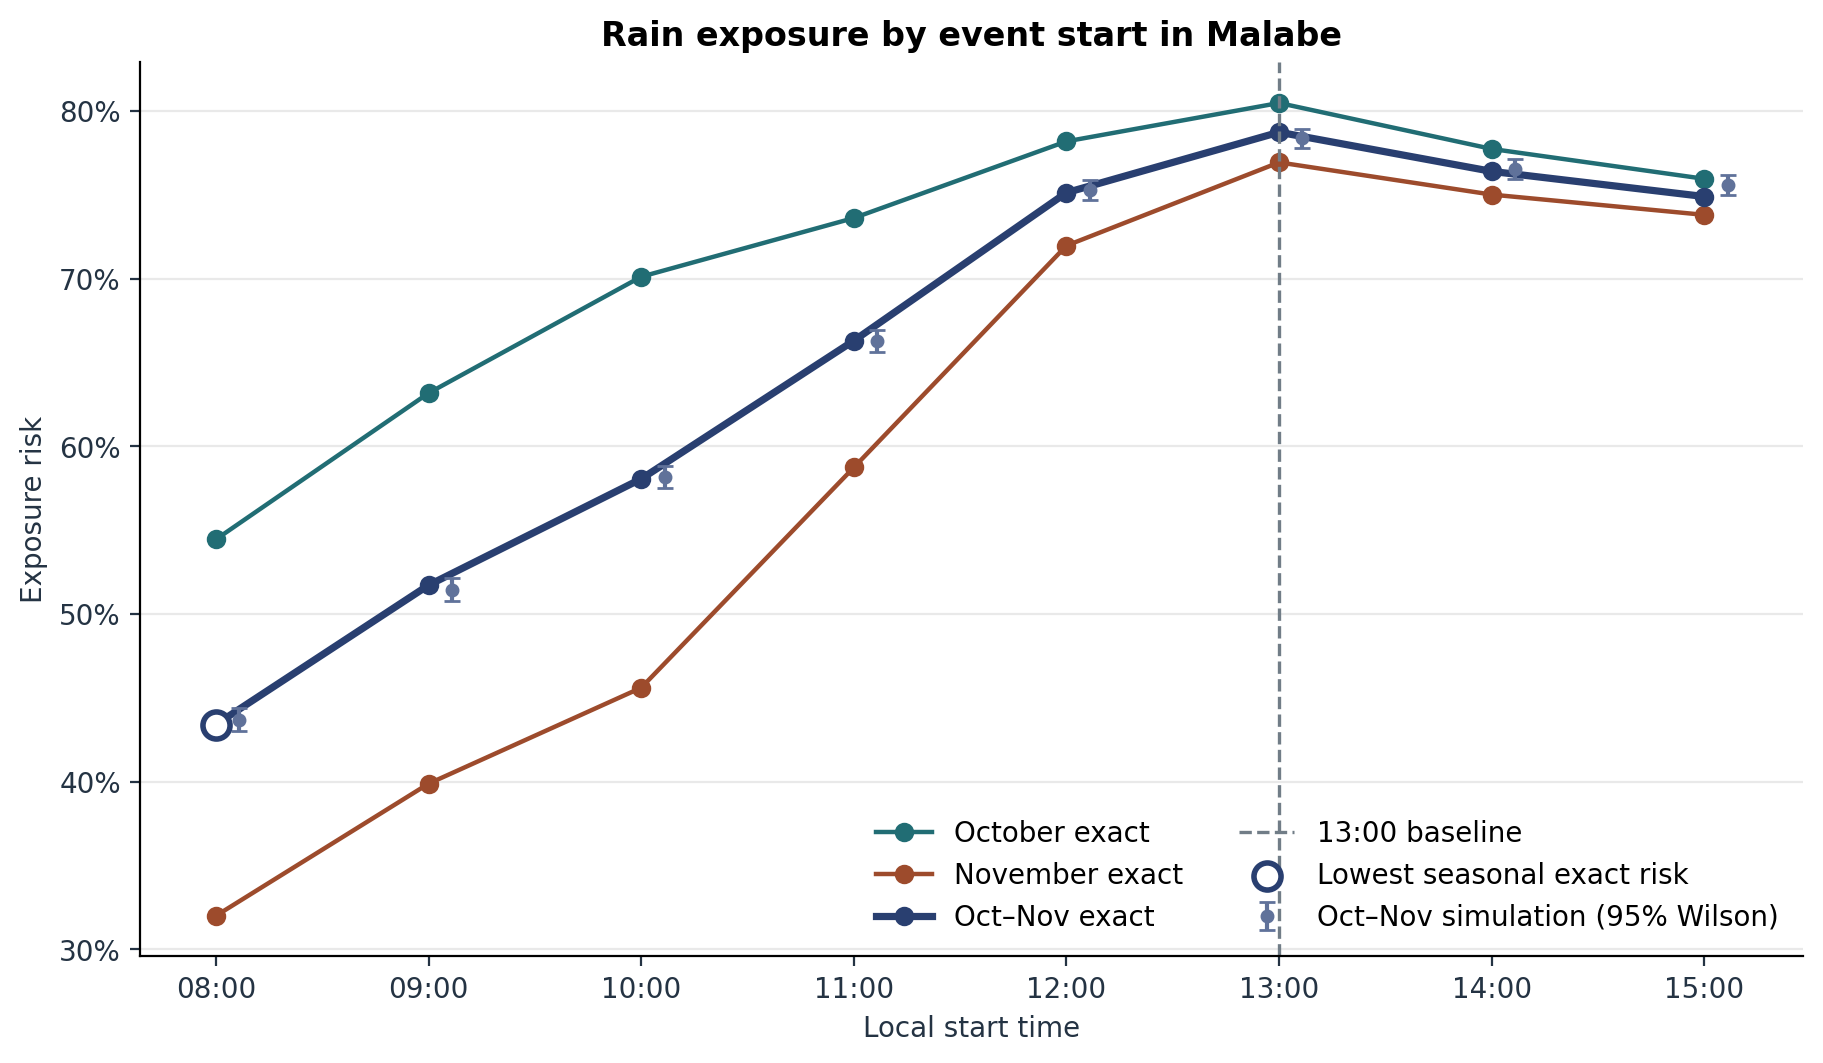

In [13]:
MAIN_TRIALS = 20_000
main_records = []
for start in START_HOURS:
    monthly = {
        month: event_probabilities(
            fitted_models, DEFAULT_THRESHOLD_MM, month, start, DEFAULT_DURATION_HOURS
        )
        for month in MONTHS
    }
    exact_monthly = {
        month: exact_markov_exposure(monthly[month][1][0], monthly[month][2])
        for month in MONTHS
    }

    for month_code in (*MONTHS, 0):
        rng = experiment_rng(main_seed, start, month_code)
        if month_code:
            month_counts = {month: MAIN_TRIALS if month == month_code else 0 for month in MONTHS}
            exact = exact_monthly[month_code]
            period = MONTH_NAMES[month_code]
        else:
            # Draw a fresh month for every event, then simulate within each assigned month.
            event_months = rng.choice(MONTHS, size=MAIN_TRIALS, p=SEASON_WEIGHTS)
            month_counts = {month: int((event_months == month).sum()) for month in MONTHS}
            exact = sum(MONTH_WEIGHTS[month] * exact_monthly[month] for month in MONTHS)
            period = POOLED_NAME

        exposures = 0
        for month, count in month_counts.items():
            if count:
                _, q, transition = monthly[month]
                exposures += int(simulate_exposure(q[0], transition, count, rng).sum())
        low, high = wilson_interval(exposures, MAIN_TRIALS)
        main_records.append({
            "period": period,
            "start_hour": start,
            "duration_hours": DEFAULT_DURATION_HOURS,
            "threshold_mm": DEFAULT_THRESHOLD_MM,
            "exact_risk": exact,
            "simulated_risk": exposures / MAIN_TRIALS,
            "exposures": exposures,
            "trials": MAIN_TRIALS,
            "wilson_lower": low,
            "wilson_upper": high,
            "october_trials": month_counts[10],
            "november_trials": month_counts[11],
            "root_seed": SEED,
            "rng_spawn_key": f"0/{start}/{month_code}",
        })

main_risk = pd.DataFrame(main_records)
main_risk["exact_improvement_pp"] = baseline_differences(main_risk, "exact_risk")
main_risk["simulated_improvement_pp"] = baseline_differences(main_risk, "simulated_risk")
main_risk.to_csv(exports / "main_risk_table.csv", index=False)

season = main_risk.loc[main_risk["period"].eq(POOLED_NAME)].set_index("start_hour")
best_start = int(season["exact_risk"].idxmin())
best_risk = season.loc[best_start, "exact_risk"]
baseline_risk = season.loc[BASELINE_START_HOUR, "exact_risk"]
print(
    f"For a three-hour event at a 0.2 mm threshold, {best_start:02d}:00 had an estimated "
    f"seasonal risk of {best_risk:.1%}, compared with {baseline_risk:.1%} at 13:00. "
    f"The difference was {100 * (baseline_risk - best_risk):.1f} percentage points."
)

fig, ax = plt.subplots(figsize=(9.0, 5.2), layout="constrained")
for period in PERIOD_NAMES:
    line = main_risk.loc[main_risk["period"].eq(period)]
    ax.plot(line["start_hour"], 100 * line["exact_risk"], marker="o", color=PERIOD_COLOURS[period],
            linewidth=2.6 if period == POOLED_NAME else 1.6, label=f"{period} exact")
ax.errorbar(
    season.index.to_numpy() + 0.11, 100 * season["simulated_risk"],
    yerr=100 * np.vstack([season["simulated_risk"] - season["wilson_lower"],
                          season["wilson_upper"] - season["simulated_risk"]]),
    fmt="o", markersize=4, capsize=3, color="#60729A", label="Oct–Nov simulation (95% Wilson)",
)
ax.axvline(BASELINE_START_HOUR, color="#717D87", linestyle="--", linewidth=1.2, label="13:00 baseline")
ax.scatter(best_start, 100 * best_risk, s=95, facecolors="white", edgecolors="#293F70",
           linewidths=2, zorder=5, label="Lowest seasonal exact risk")
ax.set(title="Rain exposure by event start in Malabe", xlabel="Local start time", ylabel="Exposure risk",
       xticks=START_HOURS, xticklabels=START_LABELS)
ax.yaxis.set_major_formatter(PercentFormatter())
ax.grid(axis="y")
ax.legend(ncol=2, frameon=False, loc="best")
save_figure(fig, "main_risk_by_start.png")

### Monte Carlo error scaling

The independent all-dry and certain-wet tests are above. Use the October 08:00 scenario for scaling, because its exact risk is away from zero and one. Compare the error across 80 repeats at each sample size with the theoretical binomial RMSE.

October 08:00 exact risk 0.544430, measured log–log RMSE slope -0.502.


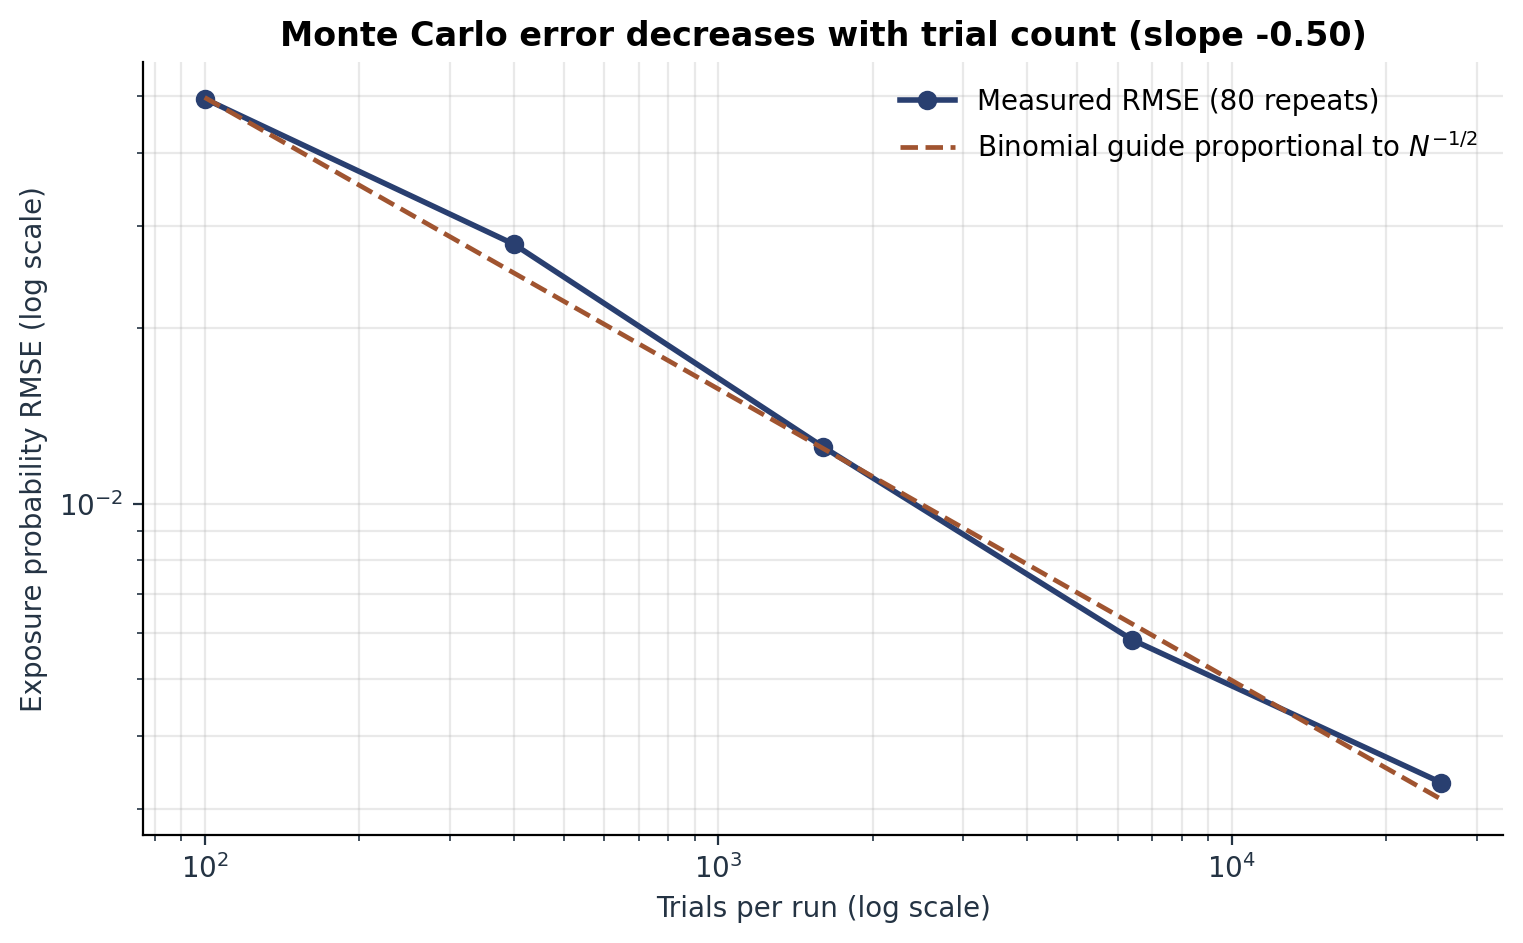

In [14]:
SCALE_SIZES = (100, 400, 1_600, 6_400, 25_600)
SCALE_REPEATS = 80
scale_reference = example_exact
scale_rows = []
for n in SCALE_SIZES:
    for repeat in range(SCALE_REPEATS):
        rng = experiment_rng(scaling_seed, n, repeat)
        estimate = simulate_exposure(hourly_wet[0], transition_wet, n, rng).mean()
        scale_rows.append({
            "trials": n,
            "repeat": repeat + 1,
            "estimate": estimate,
            "exact_risk": scale_reference,
            "error": estimate - scale_reference,
            "root_seed": SEED,
            "rng_spawn_key": f"1/{n}/{repeat}",
        })

scaling_errors = pd.DataFrame(scale_rows)
scaling_errors.to_csv(exports / "x2_mc_errors.csv", index=False)
scaling_table = (
    scaling_errors.assign(squared_error=scaling_errors["error"] ** 2)
    .groupby("trials", as_index=False)
    .agg(repeats=("error", "size"), mean_squared_error=("squared_error", "mean"))
)
scaling_table["rmse"] = np.sqrt(scaling_table["mean_squared_error"])
scaling_table["binomial_guide"] = np.sqrt(
    scale_reference * (1 - scale_reference) / scaling_table["trials"]
)
scaling_slope = np.polyfit(np.log(scaling_table["trials"]), np.log(scaling_table["rmse"]), 1)[0]
scaling_table["fitted_log_log_slope"] = scaling_slope
scaling_table.to_csv(exports / "x2_mc_error_scaling.csv", index=False)
print(f"October 08:00 exact risk {scale_reference:.6f}, measured log–log RMSE slope {scaling_slope:.3f}.")

fig, ax = plt.subplots(figsize=(7.5, 4.6), layout="constrained")
ax.loglog(scaling_table["trials"], scaling_table["rmse"], "o-", color="#293F70", linewidth=2,
          label=f"Measured RMSE ({SCALE_REPEATS} repeats)")
ax.loglog(scaling_table["trials"], scaling_table["binomial_guide"], "--", color="#A05430",
          linewidth=1.7, label=r"Binomial guide proportional to $N^{-1/2}$")
ax.set(title=f"Monte Carlo error decreases with trial count (slope {scaling_slope:.2f})",
       xlabel="Trials per run (log scale)", ylabel="Exposure probability RMSE (log scale)")
ax.grid(which="both")
ax.legend(frameon=False)
save_figure(fig, "x2_mc_error_scaling.png")

### Held-out comparison

Hold back all 2023–2025 dates from fitting. Score both forecasts on the same complete event windows. The pooled comparison weights each valid date-window equally, and its table records the number used and the October weight.

Windows evaluated on 2023–2025: 1,464/1,464, 0 excluded.
  period  valid_windows  markov_brier  independent_brier
November            720       0.20545            0.20222
 October            744       0.20606            0.24748
 Oct–Nov           1464       0.20576            0.22522
The pooled comparison weights each valid window equally. Windows from the same date overlap.


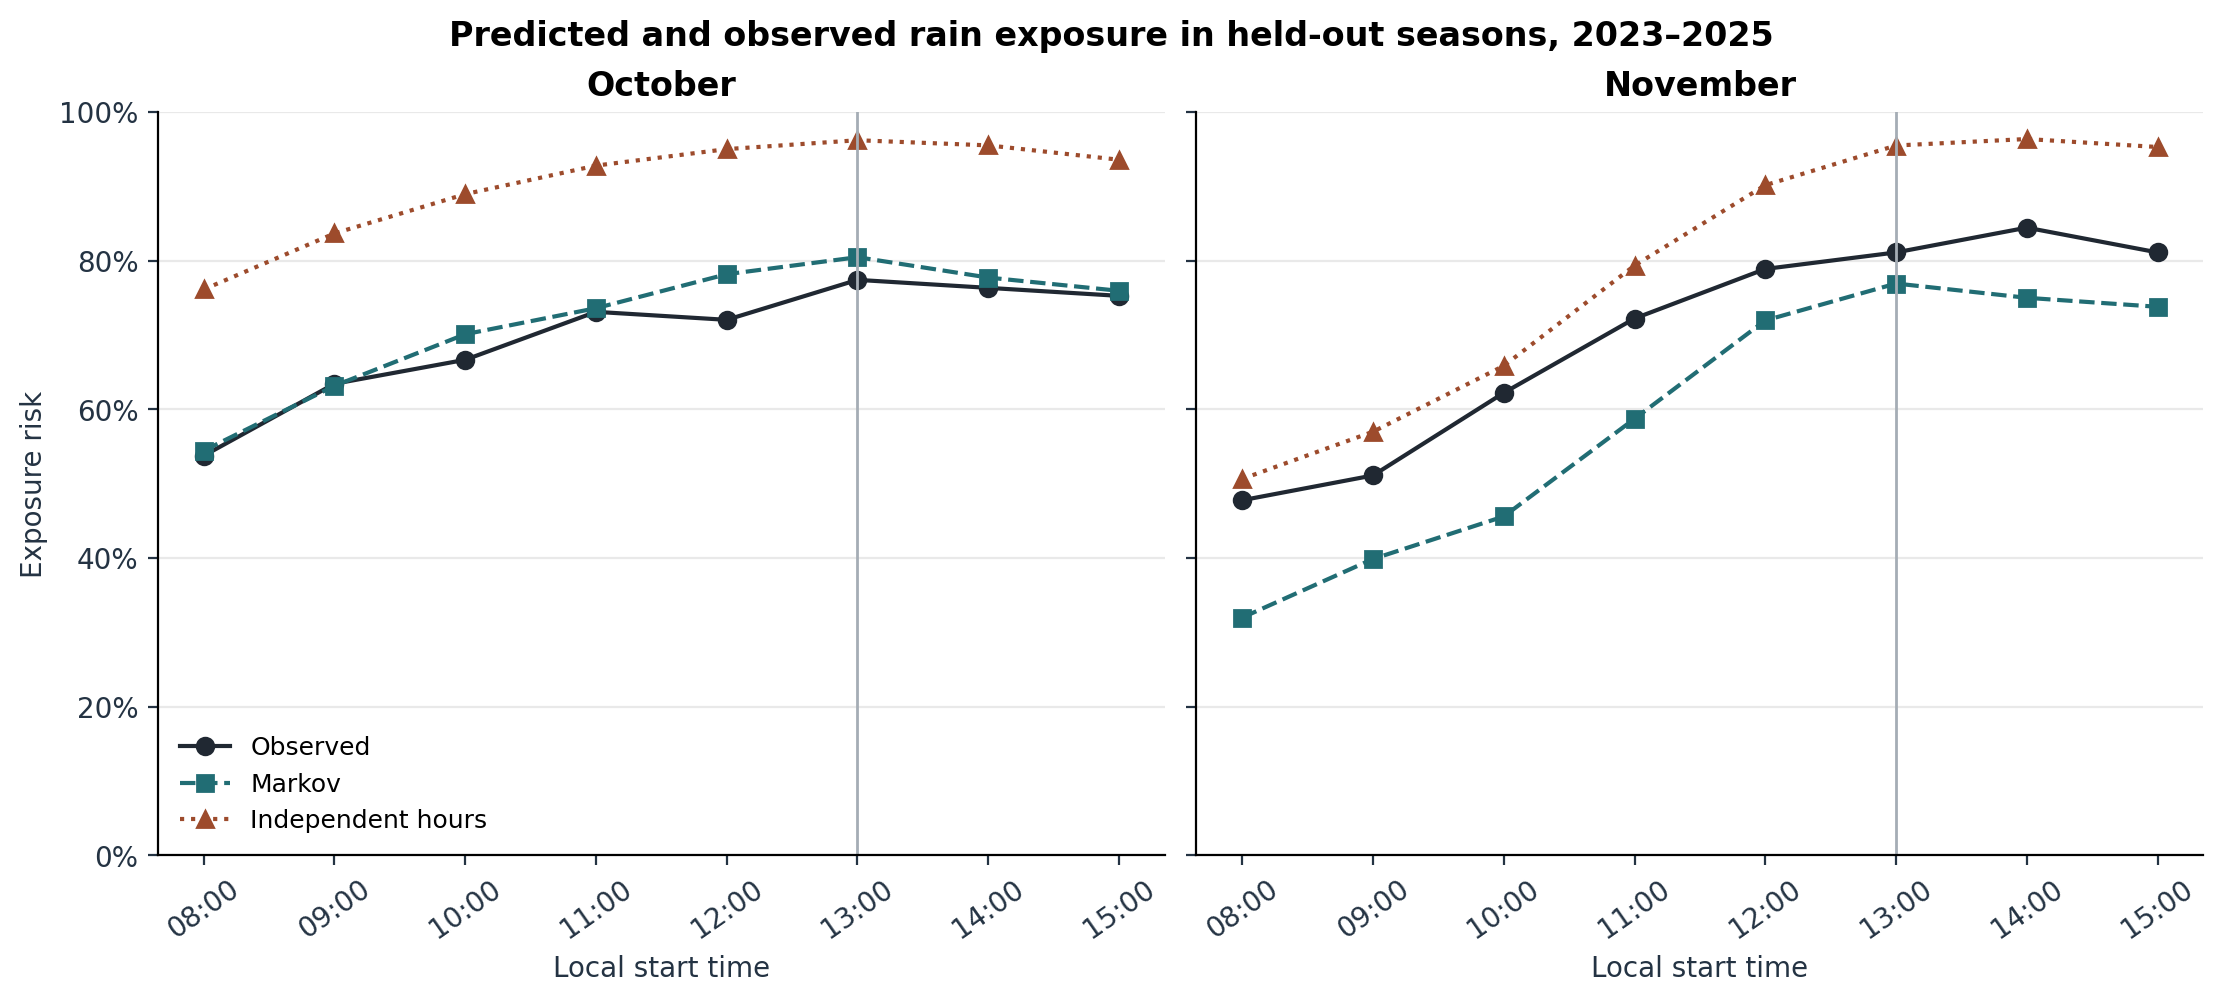

In [15]:
monthly_forecasts = {}
for month in MONTHS:
    for start in START_HOURS:
        _, q, transition = event_probabilities(
            fitted_models, DEFAULT_THRESHOLD_MM, month, start, DEFAULT_DURATION_HOURS
        )
        monthly_forecasts[month, start] = (
            exact_markov_exposure(q[0], transition), independent_hour_exposure(q)
        )

heldout_hourly = test.set_index("local_start")["local_hour_mm"]
window_records = []
for year in HELD_OUT_YEARS:
    for month in MONTHS:
        days = pd.date_range(
            f"{year}-{month:02d}-01", periods=monthrange(year, month)[1],
            freq="D", tz=LOCAL_TIME_ZONE,
        )
        for day in days:
            for start in START_HOURS:
                interval_starts = pd.date_range(
                    day + pd.Timedelta(hours=start), periods=DEFAULT_DURATION_HOURS, freq="h"
                )
                totals = heldout_hourly.reindex(interval_starts)
                valid = bool(totals.notna().all())
                markov, independent = monthly_forecasts[month, start]
                window_records.append({
                    "local_date": day.date().isoformat(),
                    "month": month,
                    "period": MONTH_NAMES[month],
                    "start_hour": start,
                    "valid_window": valid,
                    "observed_exposed": int(totals.ge(DEFAULT_THRESHOLD_MM).any()) if valid else pd.NA,
                    "markov_prediction": markov,
                    "independent_prediction": independent,
                })

heldout_windows = pd.DataFrame(window_records)
heldout_windows["observed_exposed"] = heldout_windows["observed_exposed"].astype("Int8")
heldout_windows.to_csv(exports / "x4_heldout_windows.csv", index=False)
scored = heldout_windows.loc[heldout_windows["valid_window"]].copy()
scored["markov_squared_error"] = (scored["markov_prediction"] - scored["observed_exposed"]) ** 2
scored["independent_squared_error"] = (scored["independent_prediction"] - scored["observed_exposed"]) ** 2


def holdout_summary(windows, scored_windows, keys):
    attempted = windows.groupby(keys).size().rename("possible_windows")
    summary = scored_windows.groupby(keys).agg(
        valid_windows=("observed_exposed", "size"),
        exposed_windows=("observed_exposed", "sum"),
        markov_risk=("markov_prediction", "mean"),
        independent_risk=("independent_prediction", "mean"),
        october_windows=("month", lambda months: months.eq(10).sum()),
    ).reindex(attempted.index)
    counts = ["valid_windows", "exposed_windows", "october_windows"]
    summary[counts] = summary[counts].fillna(0).astype(int)
    summary["possible_windows"] = attempted
    summary["excluded_windows"] = attempted - summary["valid_windows"]
    denominator = summary["valid_windows"].where(summary["valid_windows"].gt(0))
    summary["observed_risk"] = summary["exposed_windows"] / denominator
    summary["october_weight"] = summary["october_windows"] / denominator
    return summary.reset_index()


heldout_monthly = holdout_summary(heldout_windows, scored, ["period", "start_hour"])
heldout_pooled = holdout_summary(heldout_windows, scored, ["start_hour"]).assign(period=POOLED_NAME)
heldout_comparison = pd.concat([heldout_monthly, heldout_pooled], ignore_index=True)
heldout_comparison.to_csv(exports / "x4_heldout_comparison.csv", index=False)

error_columns = ["markov_squared_error", "independent_squared_error"]
brier_scores = (
    scored.groupby("period").agg(
        valid_windows=("observed_exposed", "size"),
        markov_brier=("markov_squared_error", "mean"),
        independent_brier=("independent_squared_error", "mean"),
    ).reset_index()
)
overall = scored[error_columns].mean()
brier_scores.loc[len(brier_scores)] = [POOLED_NAME, len(scored), *overall]
brier_scores.to_csv(exports / "x4_brier_scores.csv", index=False)
print(f"Windows evaluated on 2023–2025: {len(scored):,}/{len(heldout_windows):,}, "
      f"{len(heldout_windows) - len(scored):,} excluded.")
print(brier_scores.to_string(index=False, float_format="{:.5f}".format))
print("The pooled comparison weights each valid window equally. Windows from the same date overlap.")

fig, axes = plt.subplots(1, 2, figsize=(11.0, 4.9), sharey=True, layout="constrained")
for month, ax in zip(MONTHS, axes):
    period = MONTH_NAMES[month]
    rows = heldout_monthly.loc[heldout_monthly["period"].eq(period)]
    ax.plot(rows["start_hour"], 100 * rows["observed_risk"], "o-", color="#202832", label="Observed")
    ax.plot(rows["start_hour"], 100 * rows["markov_risk"], "s--", color="#216D74", label="Markov")
    ax.plot(rows["start_hour"], 100 * rows["independent_risk"], "^:", color="#9D4B2C", label="Independent hours")
    ax.axvline(BASELINE_START_HOUR, color="#A5ADB5", linewidth=1)
    ax.set(title=period, xlabel="Local start time", xticks=START_HOURS,
           xticklabels=START_LABELS, ylim=(0, 100))
    ax.tick_params(axis="x", labelrotation=35)
    ax.yaxis.set_major_formatter(PercentFormatter())
    ax.grid(axis="y")
axes[0].set_ylabel("Exposure risk")
axes[0].legend(frameon=False, fontsize=9)
fig.suptitle("Predicted and observed rain exposure in held-out seasons, 2023–2025", fontweight="bold")
save_figure(fig, "x4_heldout_comparison.png")

### Sensitivity to event settings and time alignment

Reuse the four threshold fits for the full setting sweep. Compare the three alignments on the same training dates with valid windows under each alignment. The headline heatmaps combine the months by calendar-day weights.

Average risk span when varying one input and holding the others fixed
  variable  mean_risk_span_pp
 Threshold               46.4
Start time               34.1
  Duration               22.4

Lowest seasonal risk by threshold and duration
 threshold_mm  duration_hours  start_hour  exact_risk
        0.100               1           8       0.417
        0.100               2           8       0.547
        0.100               3           8       0.664
        0.100               4           8       0.744
        0.200               1           8       0.244
        0.200               2           8       0.339
        0.200               3           8       0.434
        0.200               4           8       0.546
        0.500               1           8       0.101
        0.500               2           8       0.136
        0.500               3           8       0.169
        0.500               4           8       0.244
        1.000               1           8       0.044
      

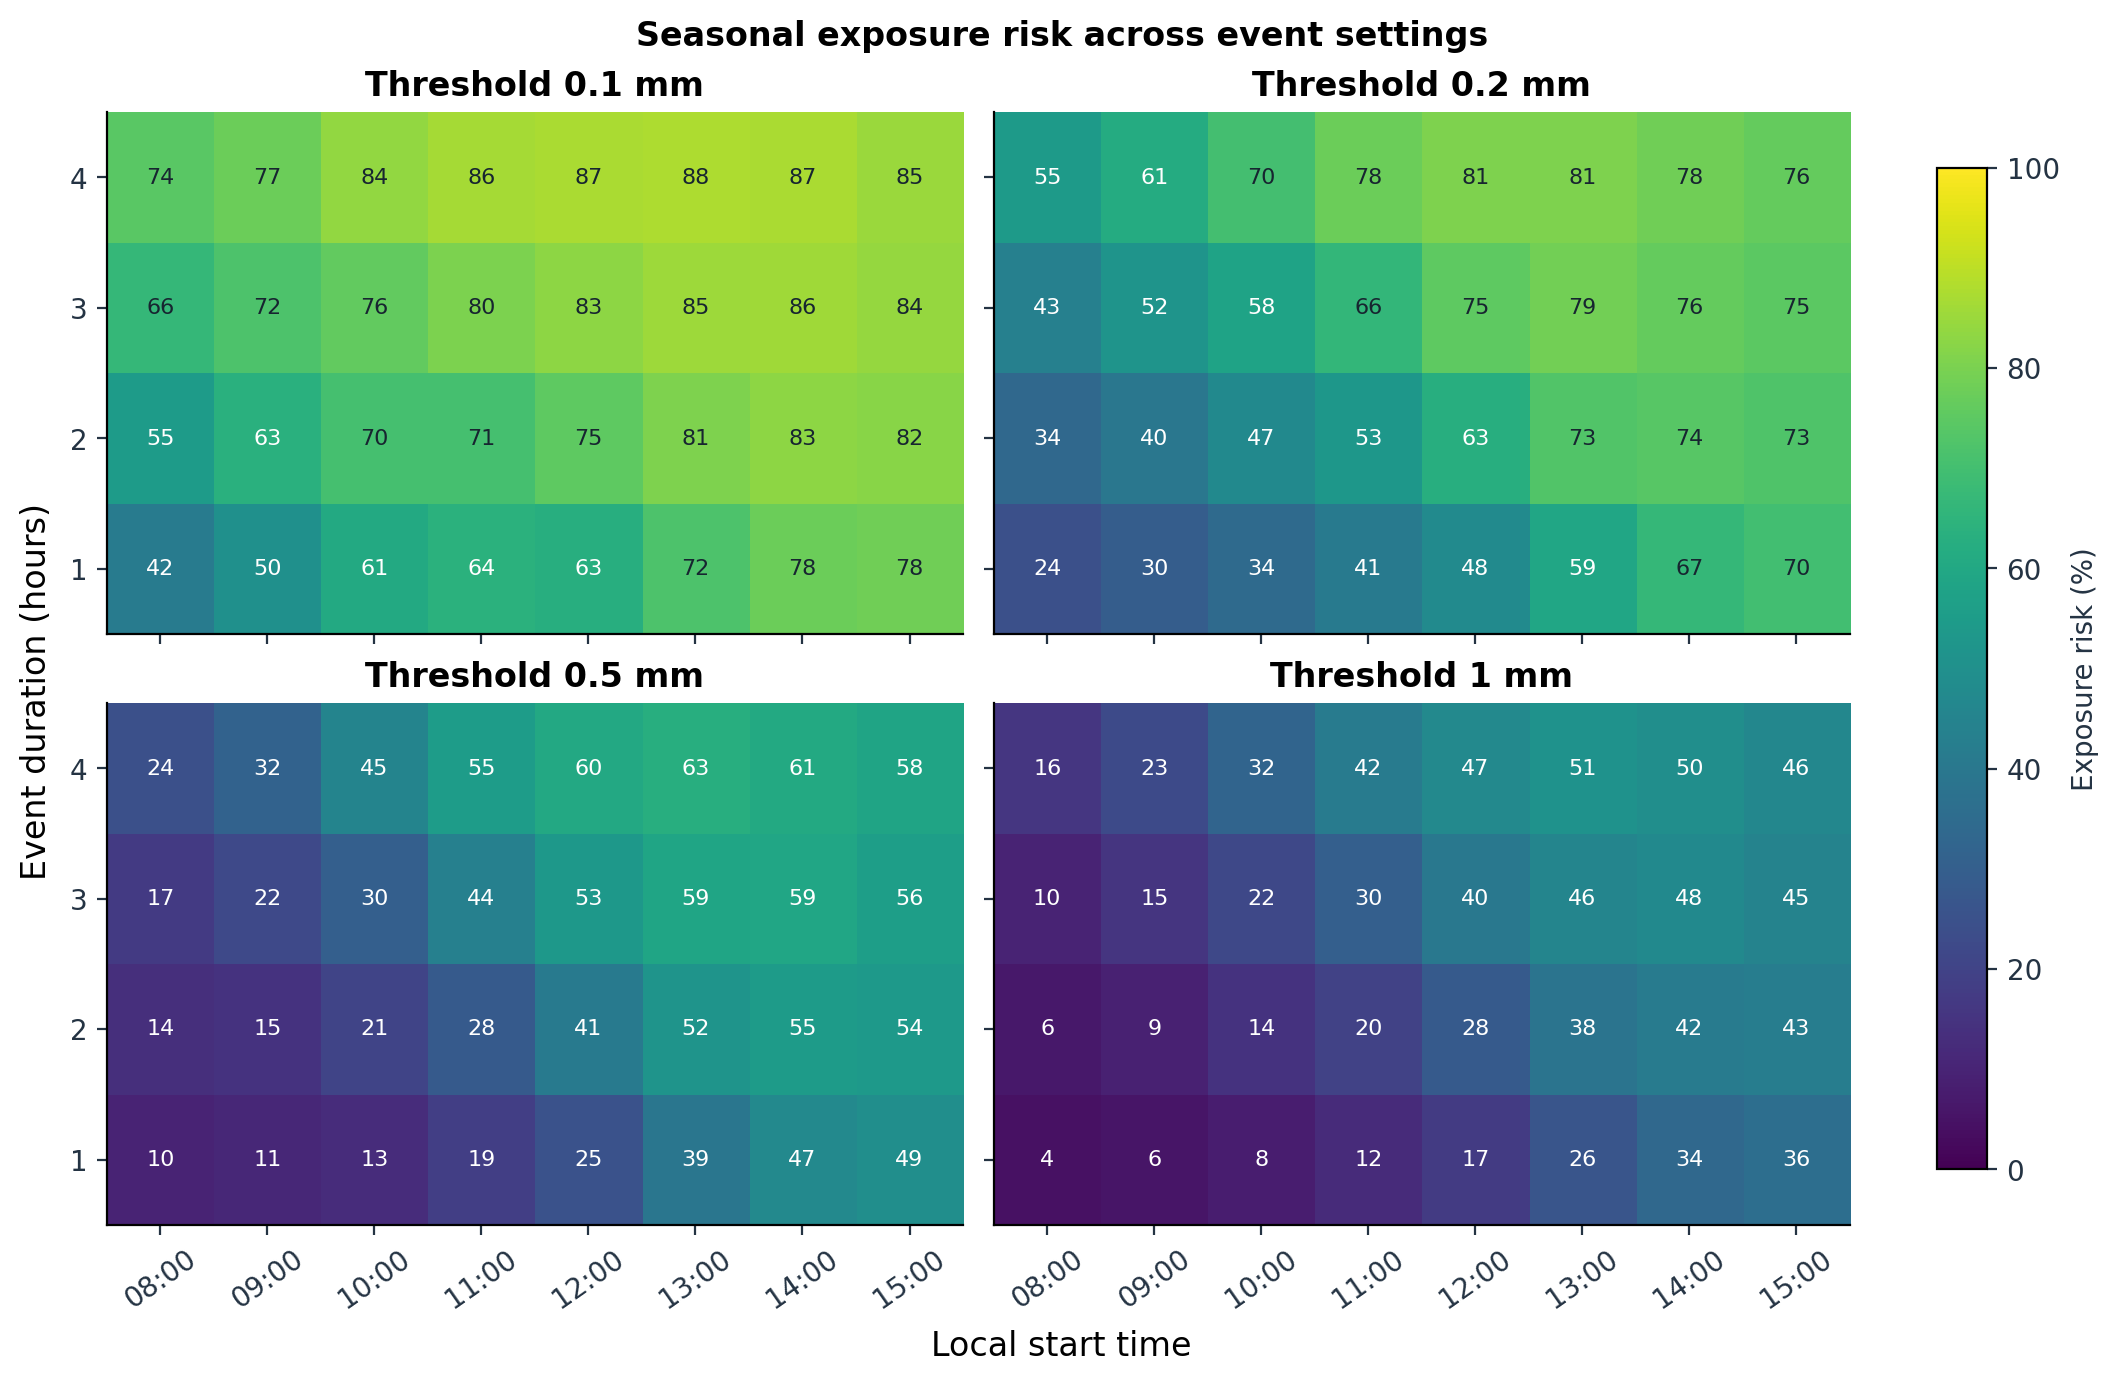

In [16]:
sweep_rows = []
for threshold in THRESHOLDS_MM:
    for duration in DURATIONS_HOURS:
        profiles = exact_profiles(fitted_models, threshold, duration)
        for period, risks in zip(PERIOD_NAMES, profiles):
            for start, risk in zip(START_HOURS, risks):
                sweep_rows.append({
                    "period": period,
                    "threshold_mm": threshold,
                    "duration_hours": duration,
                    "start_hour": start,
                    "exact_risk": risk,
                    "improvement_pp": 100 * (risks[BASELINE_INDEX] - risk),
                })
sensitivity_table = pd.DataFrame(sweep_rows)
sensitivity_table.to_csv(exports / "x5_sensitivity.csv", index=False)
pooled_sweep = sensitivity_table.loc[sensitivity_table["period"].eq(POOLED_NAME)]
pooled_settings = pooled_sweep.groupby(["threshold_mm", "duration_hours"])
best_setting_rows = pooled_sweep.loc[pooled_settings["exact_risk"].idxmin()].copy()

driver_spans = []
for variable, fixed in {
    "Start time": ["threshold_mm", "duration_hours"],
    "Duration": ["threshold_mm", "start_hour"],
    "Threshold": ["duration_hours", "start_hour"],
}.items():
    extrema = pooled_sweep.groupby(fixed)["exact_risk"].agg(["min", "max"])
    driver_spans.append({
        "variable": variable,
        "mean_risk_span_pp": 100 * (extrema["max"] - extrema["min"]).mean(),
    })
driver_table = pd.DataFrame(driver_spans).sort_values("mean_risk_span_pp", ascending=False)
driver_table.to_csv(exports / "x5_driver_spans.csv", index=False)
print("Average risk span when varying one input and holding the others fixed")
print(driver_table.to_string(index=False, float_format="{:.1f}".format))
print("\nLowest seasonal risk by threshold and duration")
print(best_setting_rows[["threshold_mm", "duration_hours", "start_hour", "exact_risk"]]
      .to_string(index=False, float_format="{:.3f}".format))

fig, axes = plt.subplots(2, 2, figsize=(10.5, 6.8), layout="constrained", sharex=True, sharey=True)
for threshold, ax in zip(THRESHOLDS_MM, axes.flat):
    panel = pooled_sweep.loc[pooled_sweep["threshold_mm"].eq(threshold)]
    risk_grid = panel.pivot(index="duration_hours", columns="start_hour", values="exact_risk")
    heat = ax.imshow(100 * risk_grid, vmin=0, vmax=100, cmap="viridis", aspect="auto", origin="lower")
    for row, risks in enumerate(risk_grid.to_numpy()):
        for column, risk in enumerate(risks):
            ax.text(column, row, f"{100*risk:.0f}", ha="center", va="center", fontsize=8,
                    color="#172530" if risk > 0.64 else "white")
    ax.set(title=f"Threshold {threshold:g} mm", xticks=range(len(START_HOURS)), xticklabels=START_LABELS,
           yticks=range(len(DURATIONS_HOURS)), yticklabels=DURATIONS_HOURS)
    ax.tick_params(axis="x", labelrotation=35)
fig.supxlabel("Local start time")
fig.supylabel("Event duration (hours)")
fig.colorbar(heat, ax=axes, label="Exposure risk (%)", shrink=0.9)
fig.suptitle("Seasonal exposure risk across event settings", fontweight="bold")
save_figure(fig, "x5_sensitivity.png")

In [17]:
# Retain dates with every hour needed by the default windows under all three alignments.
first = min(START_HOURS)
last = max(START_HOURS) + DEFAULT_DURATION_HOURS - 1
required_hours = range(first, last + 1)
timing_totals = {
    "Early bin (−30 min)": "earlier_bin_mm",
    "Clock hour overlap": "local_hour_mm",
    "Late bin (+30 min)": "later_bin_mm",
}
common_hours = train.loc[train["hour"].between(first, last)].dropna(
    subset=list(timing_totals.values())
)
usable_counts = common_hours.groupby("local_date")["hour"].nunique()
common_dates = usable_counts.index[usable_counts.eq(len(required_hours))]
timing_train = train.loc[train["local_date"].isin(common_dates)]

timing_rows = []
for label, rainfall_column in timing_totals.items():
    if rainfall_column == "local_hour_mm" and len(timing_train) == len(train):
        timing_model = fitted_models
    else:
        timing_model = {
            DEFAULT_THRESHOLD_MM: fit_hourly_markov(
                timing_train, DEFAULT_THRESHOLD_MM, rainfall_column=rainfall_column
            )
        }
    profiles = exact_profiles(timing_model, DEFAULT_THRESHOLD_MM, DEFAULT_DURATION_HOURS)
    for period, risks in zip(PERIOD_NAMES, profiles):
        for start, risk in zip(START_HOURS, risks):
            timing_rows.append({
                "alignment": label,
                "period": period,
                "start_hour": start,
                "exact_risk": risk,
                "improvement_pp": 100 * (risks[BASELINE_INDEX] - risk),
                "common_training_dates": len(common_dates),
            })

timing_table = pd.DataFrame(timing_rows)
timing_table.to_csv(exports / "x5_timing_sensitivity.csv", index=False)
pooled_timing = timing_table.loc[timing_table["period"].eq(POOLED_NAME)]
timing_best = pooled_timing.loc[pooled_timing.groupby("alignment")["exact_risk"].idxmin()]
print(f"Timing comparison on {len(common_dates)} dates with complete data across all three alignments")
print(timing_best[["alignment", "start_hour", "exact_risk"]].to_string(index=False, float_format="{:.4f}".format))

Timing comparison on 427 dates with complete data across all three alignments
          alignment  start_hour  exact_risk
 Clock hour overlap           8      0.4340
Early bin (−30 min)           8      0.5000
 Late bin (+30 min)           8      0.5901


### Fitted-parameter uncertainty

Resample seven intact training seasons with replacement 500 times. Use the same sampled years across the thresholds and sum each year's original count tables before refitting. Compare each start with 13:00 inside each replicate. The intervals use the 2.5th and 97.5th percentiles. Risks within $10^{-12}$ share a lowest-risk vote.

Fitted-parameter uncertainty: 500 resamples of 7 training seasons.
Starts covering at least 90% of lowest-risk votes: 08:00.
Starts tied within 1e-12 share one vote equally.


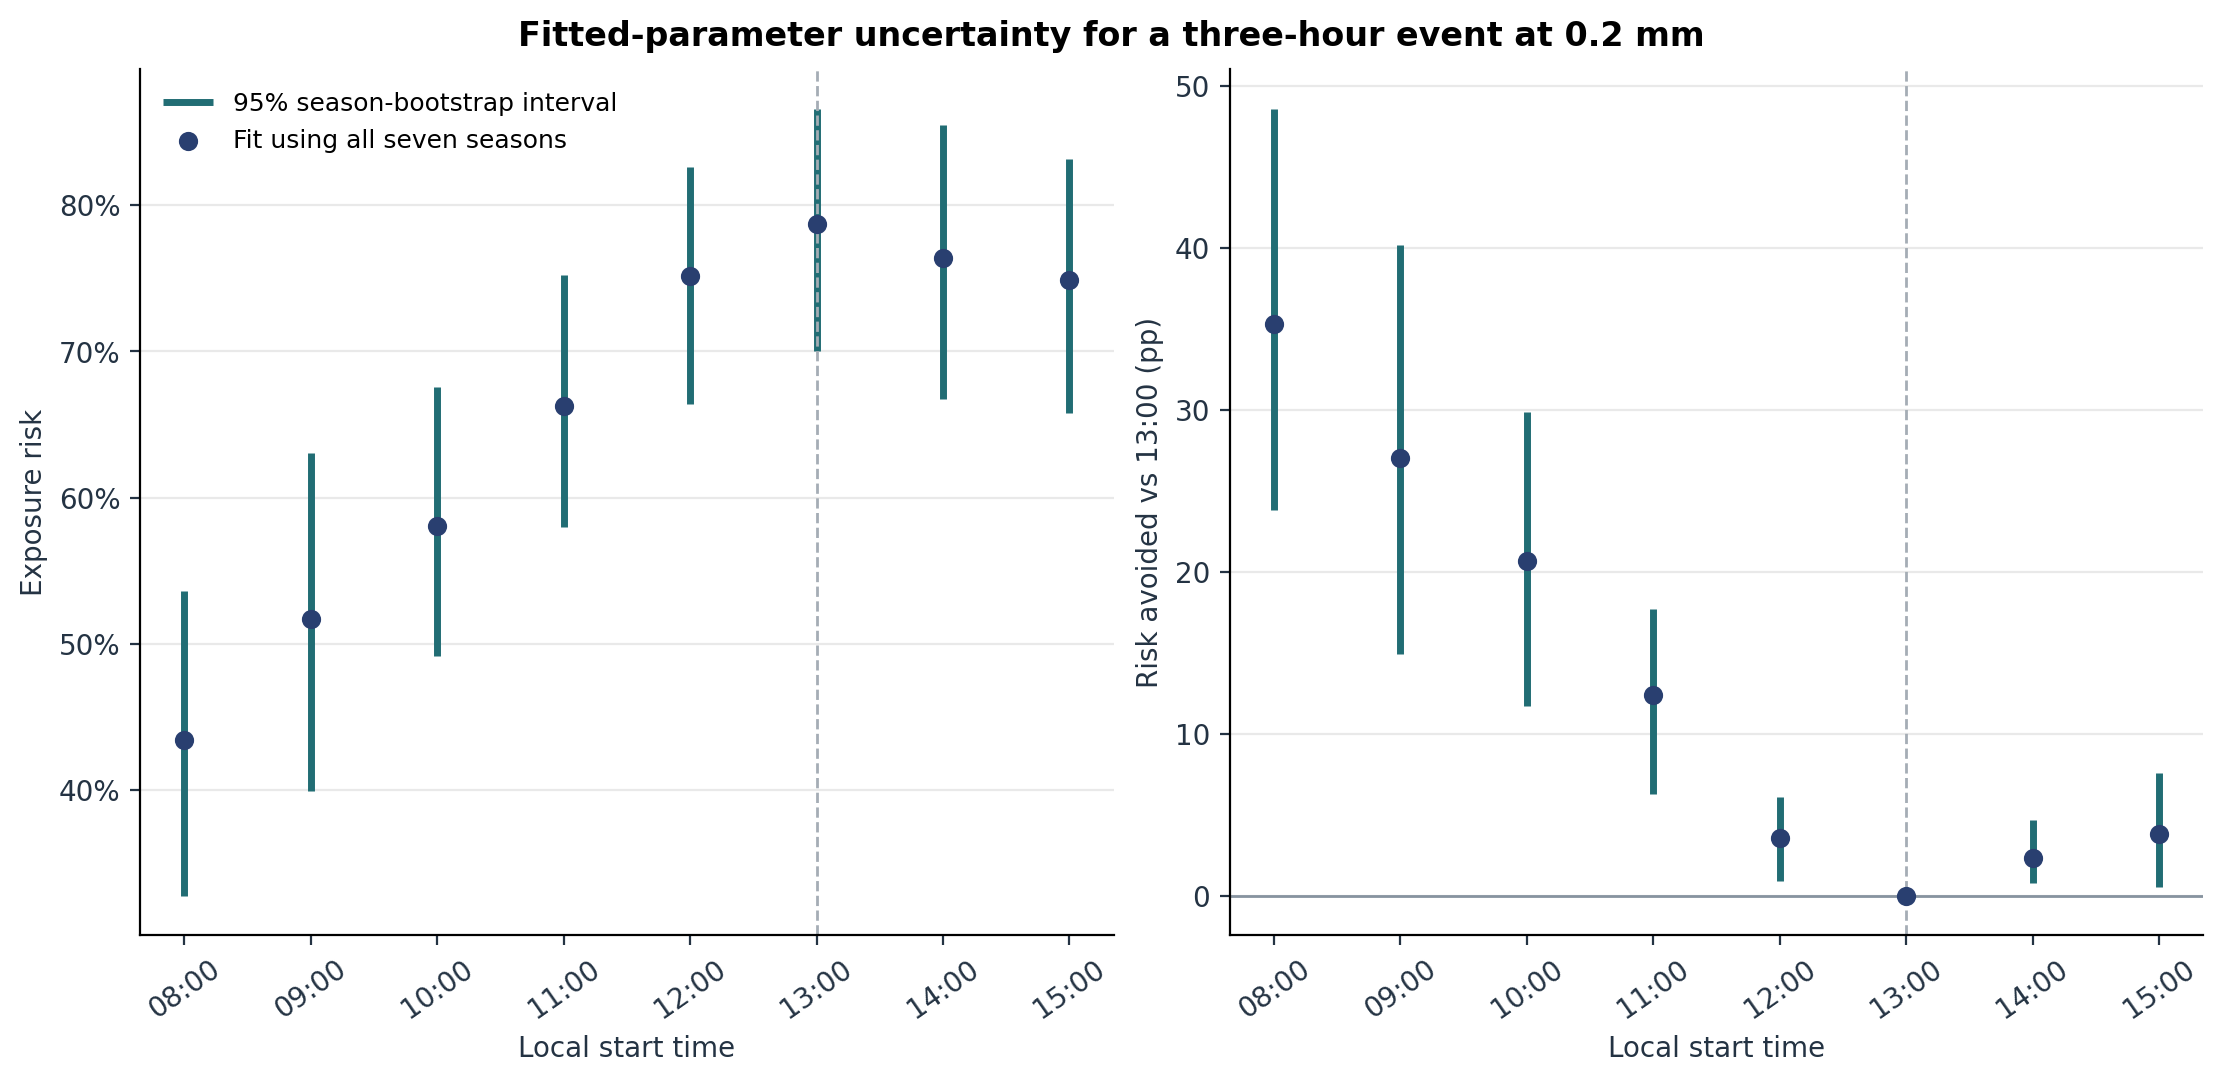

In [18]:
BOOTSTRAP_REPEATS = 500
year_values = np.asarray(TRAIN_YEARS)
year_count = len(year_values)
positions = np.random.default_rng(bootstrap_seed).integers(
    0, year_count, size=(BOOTSTRAP_REPEATS, year_count)
)
# Row b counts how often each intact training season was selected in replicate b.
multiplicity = (positions[:, :, None] == np.arange(year_count)).sum(axis=1)
draws = pd.DataFrame(year_values[positions], columns=[f"draw_{i+1}" for i in range(year_count)])
draws.insert(0, "replicate", np.arange(1, BOOTSTRAP_REPEATS + 1))
draws.to_csv(exports / "x5_bootstrap_draws.csv", index=False)

training_seasons = [
    train.loc[train["year"].eq(year)] for year in TRAIN_YEARS
]
bootstrap_records = []
for threshold in THRESHOLDS_MM:
    annual = [fit_hourly_markov(year_data, threshold) for year_data in training_seasons]
    initial_by_year = np.stack([
        fit["initial"][["valid_hours", "wet_hours"]].to_numpy()
        for fit in annual
    ]).reshape(year_count, len(MONTHS), 24, 2)
    transitions_by_year = np.stack([
        fit["transitions"][["dry_count", "wet_count"]].to_numpy()
        for fit in annual
    ]).reshape(year_count, len(MONTHS), 23, 2, 2)

    # Add the original counts before applying the 0.5 smoothing.
    initial_counts = np.tensordot(multiplicity, initial_by_year, axes=1)
    transition_counts = np.tensordot(multiplicity, transitions_by_year, axes=1)
    if (initial_counts[..., 0] == 0).any():
        raise ValueError("A resampled initial group has no valid hours.")
    initial_wet = initial_counts[..., 1] / initial_counts[..., 0]
    transition_probabilities = (
        (transition_counts + 0.5) / (transition_counts.sum(axis=-1, keepdims=True) + 1.0)
    )
    dry_to_dry = transition_probabilities[..., 0, 0]

    for duration in DURATIONS_HOURS:
        monthly_risks = np.stack([
            # The transition array starts at destination hour 01:00.
            # Destination start+1 therefore has zero-based index start.
            1 - (1 - initial_wet[:, :, start])
            * dry_to_dry[:, :, start:start + duration - 1].prod(axis=-1)
            for start in START_HOURS
        ], axis=-1)
        seasonal_risks = np.einsum("m,bms->bs", SEASON_WEIGHTS, monthly_risks)
        all_risks = np.concatenate([monthly_risks, seasonal_risks[:, None, :]], axis=1)
        improvement_pp = 100 * (all_risks[:, :, BASELINE_INDEX, None] - all_risks)
        winners = np.isclose(all_risks, all_risks.min(axis=-1, keepdims=True), rtol=0, atol=1e-12)
        win_share = (winners / winners.sum(axis=-1, keepdims=True)).mean(axis=0)
        risk_percentiles = np.percentile(all_risks, [2.5, 97.5], axis=0)
        improvement_percentiles = np.percentile(improvement_pp, [2.5, 97.5], axis=0)

        for period_index, period in enumerate(PERIOD_NAMES):
            for start_index, start in enumerate(START_HOURS):
                bootstrap_records.append({
                    "period": period,
                    "threshold_mm": threshold,
                    "duration_hours": duration,
                    "start_hour": start,
                    "risk_lower": risk_percentiles[0, period_index, start_index],
                    "risk_upper": risk_percentiles[1, period_index, start_index],
                    "improvement_lower_pp": improvement_percentiles[0, period_index, start_index],
                    "improvement_upper_pp": improvement_percentiles[1, period_index, start_index],
                    "lowest_risk_share": win_share[period_index, start_index],
                    "replicates": BOOTSTRAP_REPEATS,
                    "training_seasons": year_count,
                    "root_seed": SEED,
                    "rng_spawn_key": "2",
                })

bootstrap_table = pd.DataFrame(bootstrap_records).merge(
    sensitivity_table,
    on=["period", "threshold_mm", "duration_hours", "start_hour"],
    validate="one_to_one",
)
bootstrap_table.to_csv(exports / "x5_bootstrap_intervals.csv", index=False)
default_intervals = bootstrap_table.loc[
    bootstrap_table["period"].eq(POOLED_NAME)
    & bootstrap_table["duration_hours"].eq(DEFAULT_DURATION_HOURS)
    & bootstrap_table["threshold_mm"].eq(DEFAULT_THRESHOLD_MM)
].sort_values("start_hour")
best_votes = default_intervals.sort_values(["lowest_risk_share", "start_hour"], ascending=[False, True])
vote_set_size = int(np.searchsorted(best_votes["lowest_risk_share"].cumsum(), 0.9)) + 1
common_best_starts = ", ".join(f"{hour:02d}:00" for hour in best_votes["start_hour"].iloc[:vote_set_size])
print(f"Fitted-parameter uncertainty: {BOOTSTRAP_REPEATS} resamples of {year_count} training seasons.")
print(f"Starts covering at least 90% of lowest-risk votes: {common_best_starts}.")
print("Starts tied within 1e-12 share one vote equally.")

fig, axes = plt.subplots(1, 2, figsize=(11.0, 5.3), sharex=True, layout="constrained")
for ax, point, lower, upper, scale, label in [
    (axes[0], "exact_risk", "risk_lower", "risk_upper", 100, "Exposure risk"),
    (axes[1], "improvement_pp", "improvement_lower_pp", "improvement_upper_pp", 1, "Risk avoided vs 13:00 (pp)"),
]:
    ax.vlines(default_intervals["start_hour"], scale * default_intervals[lower],
              scale * default_intervals[upper], color="#216D74", linewidth=2.5,
              label="95% season-bootstrap interval")
    ax.scatter(default_intervals["start_hour"], scale * default_intervals[point],
               s=35, color="#293F70", zorder=3, label="Fit using all seven seasons")
    ax.axvline(BASELINE_START_HOUR, color="#A5ADB5", linestyle="--", linewidth=1)
    ax.set(xlabel="Local start time", ylabel=label, xticks=START_HOURS, xticklabels=START_LABELS)
    ax.tick_params(axis="x", labelrotation=35)
    ax.grid(axis="y")
axes[0].yaxis.set_major_formatter(PercentFormatter())
axes[1].axhline(0, color="#87939F", linewidth=1)
axes[0].legend(frameon=False, fontsize=9)
fig.suptitle("Fitted-parameter uncertainty for a three-hour event at 0.2 mm", fontweight="bold")
save_figure(fig, "x5_bootstrap_intervals.png")

## 6. Discussion and limitations

Treat the results as historical planning estimates. ERA5 estimates cover a grid area around Malabe, and the local-hour conversion assumes rainfall is evenly distributed within each source hour. The first-order model only remembers one hourly state. Compare the result with the half-hour timing check and held-out frequencies before choosing a start time.

Wilson intervals measure Monte Carlo sampling error for a fixed fit. The season-bootstrap intervals measure variation in the fit across seven training seasons. Held-out windows on the same date overlap, so the Brier scores describe these windows without treating them as independent evidence of a model advantage.

In [19]:
selected = default_intervals.set_index("start_hour").loc[best_start]
observed = heldout_pooled.set_index("start_hour")
observed_best = int(observed["observed_risk"].idxmin())
candidate_observed = observed.loc[best_start]
baseline_observed = observed.loc[BASELINE_START_HOUR]

print(
    f"The lowest fitted Oct–Nov risk is {best_risk:.1%} at {best_start:02d}:00. "
    f"That start received {selected['lowest_risk_share']:.1%} of the bootstrap votes."
)
print(
    f"Its estimated reduction versus 13:00 is {selected['improvement_pp']:.1f} pp "
    f"(95% season-bootstrap interval {selected['improvement_lower_pp']:.1f} "
    f"to {selected['improvement_upper_pp']:.1f} pp)."
)
print(
    f"In the holdout, {best_start:02d}:00 was exposed on "
    f"{candidate_observed['exposed_windows']:.0f}/{candidate_observed['valid_windows']:.0f} valid dates "
    f"({candidate_observed['observed_risk']:.1%}), versus "
    f"{baseline_observed['exposed_windows']:.0f}/{baseline_observed['valid_windows']:.0f} "
    f"({baseline_observed['observed_risk']:.1%}) at 13:00. "
    f"The lowest observed frequency was at {observed_best:02d}:00."
)

The lowest fitted Oct–Nov risk is 43.4% at 08:00. That start received 100.0% of the bootstrap votes.
Its estimated reduction versus 13:00 is 35.3 pp (95% season-bootstrap interval 23.8 to 48.6 pp).
In the holdout, 08:00 was exposed on 93/183 valid dates (50.8%), versus 145/183 (79.2%) at 13:00. The lowest observed frequency was at 08:00.


### Browser demo reference and export

Export the fitted probabilities at full precision. Month and threshold keys in the browser are strings. The reference uses the October 13:00 three-hour event at 0.2 mm. The browser computes its own exact risk from the same fitted probabilities to check that it uses the same hour and state conventions.

In [ ]:
reference = {
    "month": "10",
    "startHour": 13,
    "durationHours": 3,
    "threshold": "0.2",
}
_, reference_wet, reference_steps = event_probabilities(
    fitted_models,
    float(reference["threshold"]),
    int(reference["month"]),
    reference["startHour"],
    reference["durationHours"],
)
reference["probability"] = exact_markov_exposure(reference_wet[0], reference_steps)
reference["absoluteTolerance"] = 1e-12

last_hour = max(START_HOURS) + max(DURATIONS_HOURS) - 1
parameters = {}
for threshold, model in fitted_models.items():
    by_month = {}
    for month in MONTHS:
        initial = model["initial"].loc[month]
        transitions = model["transitions"].loc[month]
        by_month[str(month)] = {
            str(hour): {
                "initialWet": float(initial.loc[hour, "p_wet"]),
                "wetAfterDry": float(transitions.loc[(hour, 0), "p_wet"]),
                "wetAfterWet": float(transitions.loc[(hour, 1), "p_wet"]),
            }
            for hour in range(min(START_HOURS), last_hour + 1)
        }
    parameters[f"{threshold:g}"] = by_month

browser_config = {
    "startHours": list(START_HOURS),
    "durations": list(DURATIONS_HOURS),
    "thresholds": [f"{value:g}" for value in THRESHOLDS_MM],
    "months": {"10": "October", "11": "November"},
    "monthWeights": {str(month): weight for month, weight in MONTH_WEIGHTS.items()},
    "baselineStart": BASELINE_START_HOUR,
    "trainingYears": [min(TRAIN_YEARS), max(TRAIN_YEARS)],
    "defaults": {
        "month": "season",
        "startHour": min(START_HOURS),
        "durationHours": DEFAULT_DURATION_HOURS,
        "threshold": f"{DEFAULT_THRESHOLD_MM:g}",
    },
    "reference": reference,
    "parameters": parameters,
}
config_text = "const RAIN_CONFIG = " + json.dumps(browser_config, allow_nan=False, indent=2) + ";\n"
(exports / "rain-config.txt").write_text(config_text, encoding="utf-8", newline="\n")
print(f"Notebook reference (October 13:00, 3 hours, 0.2 mm): {reference['probability']!r}")

Notebook reference (October 13:00, 3 hours, 0.2 mm): 0.804710957771055


## 7. References

1. ECMWF, [ERA5 hourly data on single levels](https://doi.org/10.24381/cds.adbb2d47), Copernicus Climate Data Store.
2. Open-Meteo, [Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api#hourly-parameter-definition), delivery service and hourly timestamp definition.
3. H. Hersbach et al., [The ERA5 global reanalysis](https://doi.org/10.1002/qj.3803), *Quarterly Journal of the Royal Meteorological Society*, 2020.
4. OpenStreetMap contributors, [Malabe town point](https://www.openstreetmap.org/node/3274475234), representative query location.
5. E. B. Wilson, [Probable Inference, the Law of Succession, and Statistical Inference](https://doi.org/10.1080/01621459.1927.10502953), *Journal of the American Statistical Association*, 1927.
6. T. Gneiting and A. E. Raftery, [Strictly Proper Scoring Rules, Prediction, and Estimation](https://doi.org/10.1198/016214506000001437), *Journal of the American Statistical Association*, 2007.
7. H. R. Künsch, [The Jackknife and the Bootstrap for General Stationary Observations](https://doi.org/10.1214/aos/1176347265), *The Annals of Statistics*, 1989.